In [1]:

import os

dataset_path = r"E:\gda\Tess"

print("Dataset path exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    for root, dirs, files in os.walk(dataset_path):
        level = root.replace(dataset_path, "").count(os.sep)

        if level > 2:
            dirs[:] = []
            continue

        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")


Dataset path exists: True
Tess/
    features_tess.csv
    OAF_angry/
        OAF_back_angry.wav
        OAF_bar_angry.wav
        OAF_base_angry.wav
        OAF_bath_angry.wav
        OAF_bean_angry.wav
    OAF_disgust/
        OAF_back_disgust.wav
        OAF_bar_disgust.wav
        OAF_base_disgust.wav
        OAF_bath_disgust.wav
        OAF_bean_disgust.wav
    OAF_Fear/
        OAF_back_fear.wav
        OAF_bar_fear.wav
        OAF_base_fear.wav
        OAF_bath_fear.wav
        OAF_bean_fear.wav
    OAF_happy/
        OAF_back_happy.wav
        OAF_bar_happy.wav
        OAF_base_happy.wav
        OAF_bath_happy.wav
        OAF_bean_happy.wav
    OAF_neutral/
        OAF_back_neutral.wav
        OAF_bar_neutral.wav
        OAF_base_neutral.wav
        OAF_bath_neutral.wav
        OAF_bean_neutral.wav
    OAF_Pleasant_surprise/
        OAF_back_ps.wav
        OAF_bar_ps.wav
        OAF_base_ps.wav
        OAF_bath_ps.wav
        OAF_bean_ps.wav
    OAF_Sad/
        OAF_back_sad.wav

In [2]:

import os
import pandas as pd

dataset_path = r"E:\gda\Tess"

records = []

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if not os.path.isdir(folder_path):
        continue

    for filename in os.listdir(folder_path):
        if filename.lower().endswith(".wav"):
            file_path = os.path.join(folder_path, filename)

            records.append({
                "filename": filename,
                "emotion_folder": folder,
                "speaker": filename.split("_")[0],
                "file_path": file_path
            })

audio_df = pd.DataFrame(records)

print("Total audio files:", len(audio_df))
print("\nEmotion folder distribution:")
print(audio_df["emotion_folder"].value_counts().sort_index())

print("\nSpeaker distribution:")
print(audio_df["speaker"].value_counts())

print("\nMissing values:")
print(audio_df.isnull().sum())

display(audio_df.head())


Total audio files: 2800

Emotion folder distribution:
emotion_folder
OAF_Fear                  200
OAF_Pleasant_surprise     200
OAF_Sad                   200
OAF_angry                 200
OAF_disgust               200
OAF_happy                 200
OAF_neutral               200
YAF_angry                 200
YAF_disgust               200
YAF_fear                  200
YAF_happy                 200
YAF_neutral               200
YAF_pleasant_surprised    200
YAF_sad                   200
Name: count, dtype: int64

Speaker distribution:
speaker
YAF    1400
OAF    1399
OA        1
Name: count, dtype: int64

Missing values:
filename          0
emotion_folder    0
speaker           0
file_path         0
dtype: int64


,filename,emotion_folder,speaker,file_path
0,OAF_back_angry.wav,OAF_angry,OAF,E:\gda\Tess\OAF_angry\OAF_back_angry.wav
1,OAF_bar_angry.wav,OAF_angry,OAF,E:\gda\Tess\OAF_angry\OAF_bar_angry.wav
2,OAF_base_angry.wav,OAF_angry,OAF,E:\gda\Tess\OAF_angry\OAF_base_angry.wav
3,OAF_bath_angry.wav,OAF_angry,OAF,E:\gda\Tess\OAF_angry\OAF_bath_angry.wav
4,OAF_bean_angry.wav,OAF_angry,OAF,E:\gda\Tess\OAF_angry\OAF_bean_angry.wav


In [3]:

import os
import pandas as pd

# Find files whose speaker prefix is unexpected
print("Unexpected speaker prefixes:")
print(audio_df.loc[
    ~audio_df["speaker"].isin(["OAF", "YAF"]),
    ["filename", "emotion_folder", "speaker", "file_path"]
])

# Standardize emotion labels from folder names
def get_emotion(folder):
    name = folder.lower()

    if "angry" in name:
        return "angry"
    elif "disgust" in name:
        return "disgust"
    elif "fear" in name:
        return "fear"
    elif "happy" in name:
        return "happy"
    elif "neutral" in name:
        return "neutral"
    elif "sad" in name:
        return "sad"
    elif "surprise" in name or name.endswith("_ps"):
        return "surprise"
    else:
        return "unknown"

audio_df["emotion"] = audio_df["emotion_folder"].apply(get_emotion)

print("\nEmotion distribution:")
print(audio_df["emotion"].value_counts())

print("\nSpeaker-emotion distribution:")
print(pd.crosstab(audio_df["speaker"], audio_df["emotion"]))

print("\nUnknown labels:", (audio_df["emotion"] == "unknown").sum())


Unexpected speaker prefixes:
                filename emotion_folder speaker  \
999  OA_bite_neutral.wav    OAF_neutral      OA   

                                       file_path  
999  E:\gda\Tess\OAF_neutral\OA_bite_neutral.wav  

Emotion distribution:
emotion
angry       400
disgust     400
fear        400
happy       400
neutral     400
surprise    400
sad         400
Name: count, dtype: int64

Speaker-emotion distribution:
emotion  angry  disgust  fear  happy  neutral  sad  surprise
speaker                                                     
OA           0        0     0      0        1    0         0
OAF        200      200   200    200      199  200       200
YAF        200      200   200    200      200  200       200

Unknown labels: 0


In [4]:

import os
import numpy as np

try:
    import librosa
    print("Librosa version:", librosa.__version__)
except ImportError:
    print("Librosa is not installed. Run: pip install librosa")

print("\nChecking sample audio files...")

for emotion in audio_df["emotion"].unique():
    sample = audio_df.loc[
        audio_df["emotion"] == emotion, "file_path"
    ].iloc[0]

    try:
        y_audio, sr = librosa.load(sample, sr=None)
        duration = len(y_audio) / sr

        print(
            f"{emotion:10s} | "
            f"Sample rate: {sr} Hz | "
            f"Duration: {duration:.2f}s | "
            f"Valid: {len(y_audio) > 0}"
        )
    except Exception as e:
        print(f"{emotion}: ERROR - {e}")

print("\nTotal recordings:", len(audio_df))
print("Missing audio paths:", (~audio_df["file_path"].apply(os.path.isfile)).sum())


Librosa version: 0.11.0

Checking sample audio files...
angry      | Sample rate: 24414 Hz | Duration: 1.54s | Valid: True
disgust    | Sample rate: 24414 Hz | Duration: 2.26s | Valid: True
fear       | Sample rate: 24414 Hz | Duration: 1.73s | Valid: True
happy      | Sample rate: 24414 Hz | Duration: 2.00s | Valid: True
neutral    | Sample rate: 24414 Hz | Duration: 2.04s | Valid: True
surprise   | Sample rate: 24414 Hz | Duration: 2.03s | Valid: True
sad        | Sample rate: 24414 Hz | Duration: 2.56s | Valid: True

Total recordings: 2800
Missing audio paths: 0


In [5]:

import librosa
import numpy as np
import pandas as pd

def extract_features(file_path):
    y, sr = librosa.load(file_path, sr=22050, mono=True)

    # Extract MFCC features
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=13,
        n_fft=2048,
        hop_length=512
    )

    features = {}

    # Calculate mean and standard deviation of MFCCs
    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    # Extract additional acoustic features
    rms = librosa.feature.rms(y=y)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]

    features["energy_mean"] = np.mean(rms)
    features["energy_std"] = np.std(rms)
    features["zcr_mean"] = np.mean(zcr)
    features["centroid_mean"] = np.mean(centroid)
    features["bandwidth_mean"] = np.mean(bandwidth)
    features["rolloff_mean"] = np.mean(rolloff)

    return features


# Store extracted features
feature_rows = []
failed_files = []

total_files = len(audio_df)

print("Starting feature extraction...")

for i, path in enumerate(audio_df["file_path"], start=1):
    try:
        feature_rows.append(extract_features(path))

    except Exception as e:
        feature_rows.append(None)
        failed_files.append((path, str(e)))

    if i % 100 == 0 or i == total_files:
        print(f"Processed {i}/{total_files} audio files")


# Identify successfully processed files
valid_mask = [row is not None for row in feature_rows]

features_df = pd.DataFrame([
    row for row in feature_rows if row is not None
])

metadata_df = audio_df.loc[valid_mask].reset_index(drop=True)

# Combine metadata and extracted features
model_df = pd.concat(
    [
        metadata_df[["filename", "emotion", "speaker"]].reset_index(drop=True),
        features_df.reset_index(drop=True)
    ],
    axis=1
)

# Display results
print("\nFeature extraction completed!")
print("Successful recordings:", len(model_df))
print("Failed recordings:", len(failed_files))
print("Dataset shape:", model_df.shape)

print("\nEmotion distribution:")
print(model_df["emotion"].value_counts())

print("\nMissing feature values:", model_df.isna().sum().sum())

display(model_df.head())

# Display failed files, if any
if failed_files:
    print("\nFirst 5 failed files:")
    for path, error in failed_files[:5]:
        print(path, "->", error)


Starting feature extraction...
Processed 100/2800 audio files
Processed 200/2800 audio files
Processed 300/2800 audio files
Processed 400/2800 audio files
Processed 500/2800 audio files
Processed 600/2800 audio files
Processed 700/2800 audio files
Processed 800/2800 audio files
Processed 900/2800 audio files
Processed 1000/2800 audio files
Processed 1100/2800 audio files
Processed 1200/2800 audio files
Processed 1300/2800 audio files
Processed 1400/2800 audio files
Processed 1500/2800 audio files
Processed 1600/2800 audio files
Processed 1700/2800 audio files
Processed 1800/2800 audio files
Processed 1900/2800 audio files
Processed 2000/2800 audio files
Processed 2100/2800 audio files
Processed 2200/2800 audio files
Processed 2300/2800 audio files
Processed 2400/2800 audio files
Processed 2500/2800 audio files
Processed 2600/2800 audio files
Processed 2700/2800 audio files
Processed 2800/2800 audio files

Feature extraction completed!
Successful recordings: 2800
Failed recordings: 0
Da

,filename,emotion,speaker,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,...,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,energy_mean,energy_std,zcr_mean,centroid_mean,bandwidth_mean,rolloff_mean
0,OAF_back_angry.wav,angry,OAF,-383.432617,113.869888,52.460812,47.061436,-17.608944,37.845181,-11.810310,...,0.656697,10.240403,2.047498,13.852307,0.041590,0.037080,0.085165,2041.729077,2096.992664,3541.087045
1,OAF_bar_angry.wav,angry,OAF,-444.550110,114.485176,65.292038,62.193939,-2.571654,32.515205,-20.355955,...,9.995903,12.018370,-0.791078,12.628255,0.022694,0.017227,0.093492,2033.578413,2134.950293,3490.532227
2,OAF_base_angry.wav,angry,OAF,-402.192688,102.264961,26.256584,48.884304,-5.023630,29.199118,-0.407519,...,7.668492,11.588475,-0.763720,11.638530,0.029980,0.027719,0.135888,2781.496361,2428.564747,5007.112509
3,OAF_bath_angry.wav,angry,OAF,-383.497040,111.689514,52.386791,53.017384,-11.534900,40.071732,-13.975940,...,1.388642,8.746621,0.603746,11.782041,0.043182,0.038297,0.107017,2356.249716,2194.682577,4049.472656
4,OAF_bean_angry.wav,angry,OAF,-398.562683,94.341652,51.876438,49.553970,3.370301,32.785275,8.665921,...,-1.805532,11.257227,-4.849055,11.605877,0.030609,0.020426,0.081399,2190.503242,2200.942430,4082.307009


In [6]:

# 1. Check dataset size
print("Dataset shape:", model_df.shape)

# 2. Check emotion distribution
print("\nEmotion counts:")
print(model_df["emotion"].value_counts())

# 3. Check missing and infinite values
feature_cols = model_df.select_dtypes(include=np.number).columns

print("\nMissing values:", model_df[feature_cols].isna().sum().sum())
print(
    "Infinite values:",
    np.isinf(model_df[feature_cols].to_numpy()).sum()
)

# 4. Check number of speakers
print("\nSpeaker distribution:")
print(model_df["speaker"].value_counts())

# 5. Save extracted features
save_path = r"E:\gda\Tess\features_tess.csv"
model_df.to_csv(save_path, index=False)

print("\nFeatures saved successfully at:")
print(save_path)


Dataset shape: (2800, 35)

Emotion counts:
emotion
angry       400
disgust     400
fear        400
happy       400
neutral     400
surprise    400
sad         400
Name: count, dtype: int64

Missing values: 0
Infinite values: 0

Speaker distribution:
speaker
YAF    1400
OAF    1399
OA        1
Name: count, dtype: int64

Features saved successfully at:
E:\gda\Tess\features_tess.csv


In [7]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Remove the single malformed speaker-label row
data = model_df[model_df["speaker"].isin(["OAF", "YAF"])].copy()

# Separate input features and target
X = data.drop(columns=["filename", "emotion", "speaker"])
y = data["emotion"]

# Create a stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nTraining emotion distribution:")
print(y_train.value_counts())

print("\nTesting emotion distribution:")
print(y_test.value_counts())


Training samples: 2239
Testing samples: 560
Number of features: 32

Training emotion distribution:
emotion
disgust     320
surprise    320
happy       320
angry       320
sad         320
fear        320
neutral     319
Name: count, dtype: int64

Testing emotion distribution:
emotion
fear        80
happy       80
disgust     80
sad         80
surprise    80
neutral     80
angry       80
Name: count, dtype: int64


In [8]:

# Train the LDA model
lda_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis())
])

lda_model.fit(X_train, y_train)

# Predict emotions on test data
y_pred = lda_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print("===== LDA MODEL RESULTS =====")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nEmotion label order:")
print(lda_model.named_steps["lda"].classes_)


===== LDA MODEL RESULTS =====
Accuracy: 0.9643 (96.43%)
Macro F1-score: 0.9643

Classification Report:
              precision    recall  f1-score   support

       angry       0.99      0.97      0.98        80
     disgust       0.93      1.00      0.96        80
        fear       1.00      0.97      0.99        80
       happy       0.96      0.94      0.95        80
     neutral       0.99      0.94      0.96        80
         sad       0.94      0.99      0.96        80
    surprise       0.95      0.94      0.94        80

    accuracy                           0.96       560
   macro avg       0.97      0.96      0.96       560
weighted avg       0.97      0.96      0.96       560


Confusion Matrix:
[[78  2  0  0  0  0  0]
 [ 0 80  0  0  0  0  0]
 [ 1  0 78  1  0  0  0]
 [ 0  1  0 75  0  0  4]
 [ 0  0  0  0 75  5  0]
 [ 0  0  0  0  1 79  0]
 [ 0  3  0  2  0  0 75]]

Emotion label order:
['angry' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']


In [9]:

import numpy as np
from scipy.special import logsumexp
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler

# Convert features to numerical arrays
X_train_array = X_train.to_numpy(dtype=float)
X_test_array = X_test.to_numpy(dtype=float)

# Standardize using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_array)
X_test_scaled = scaler.transform(X_test_array)

y_train_array = y_train.to_numpy()
y_test_array = y_test.to_numpy()

# Get emotion classes
classes = np.unique(y_train_array)
n_samples, n_features = X_train_scaled.shape
n_classes = len(classes)

# Store GDA parameters
priors = {}
means = {}
covariances = {}

# Estimate class priors and class means
for emotion in classes:
    X_class = X_train_scaled[y_train_array == emotion]

    priors[emotion] = len(X_class) / n_samples
    means[emotion] = np.mean(X_class, axis=0)

# Estimate the shared covariance matrix
shared_covariance = np.zeros((n_features, n_features))

for emotion in classes:
    X_class = X_train_scaled[y_train_array == emotion]
    centered = X_class - means[emotion]
    shared_covariance += centered.T @ centered

shared_covariance /= n_samples

# Add a small regularization term for numerical stability
shared_covariance += 1e-6 * np.eye(n_features)

# Precompute inverse and log determinant
sign, log_det = np.linalg.slogdet(shared_covariance)

if sign <= 0:
    raise ValueError("Covariance matrix is not positive definite.")

covariance_inverse = np.linalg.inv(shared_covariance)

# Calculate log posterior scores
def predict_gda(X):
    scores = []

    for emotion in classes:
        mean = means[emotion]
        difference = X - mean

        mahalanobis = np.sum(
            (difference @ covariance_inverse) * difference,
            axis=1
        )

        score = (
            np.log(priors[emotion])
            - 0.5 * mahalanobis
            - 0.5 * log_det
        )

        scores.append(score)

    scores = np.column_stack(scores)
    return classes[np.argmax(scores, axis=1)]

# Predict test emotions
gda_predictions = predict_gda(X_test_scaled)

# Evaluate GDA
gda_accuracy = accuracy_score(y_test_array, gda_predictions)
gda_macro_f1 = f1_score(
    y_test_array,
    gda_predictions,
    average="macro"
)

print("===== GDA FROM SCRATCH RESULTS =====")
print(f"Accuracy: {gda_accuracy * 100:.2f}%")
print(f"Macro F1-score: {gda_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_array,
    gda_predictions,
    zero_division=0
))

print("Estimated class priors:")
for emotion in classes:
    print(f"{emotion}: {priors[emotion]:.4f}")

print("\nShared covariance matrix shape:", shared_covariance.shape)
print("Number of emotion classes:", n_classes)
print("Number of input features:", n_features)


===== GDA FROM SCRATCH RESULTS =====
Accuracy: 96.43%
Macro F1-score: 0.9643

Classification Report:
              precision    recall  f1-score   support

       angry       0.99      0.97      0.98        80
     disgust       0.93      1.00      0.96        80
        fear       1.00      0.97      0.99        80
       happy       0.96      0.94      0.95        80
     neutral       0.99      0.94      0.96        80
         sad       0.94      0.99      0.96        80
    surprise       0.95      0.94      0.94        80

    accuracy                           0.96       560
   macro avg       0.97      0.96      0.96       560
weighted avg       0.97      0.96      0.96       560

Estimated class priors:
angry: 0.1429
disgust: 0.1429
fear: 0.1429
happy: 0.1429
neutral: 0.1425
sad: 0.1429
surprise: 0.1429

Shared covariance matrix shape: (32, 32)
Number of emotion classes: 7
Number of input features: 32


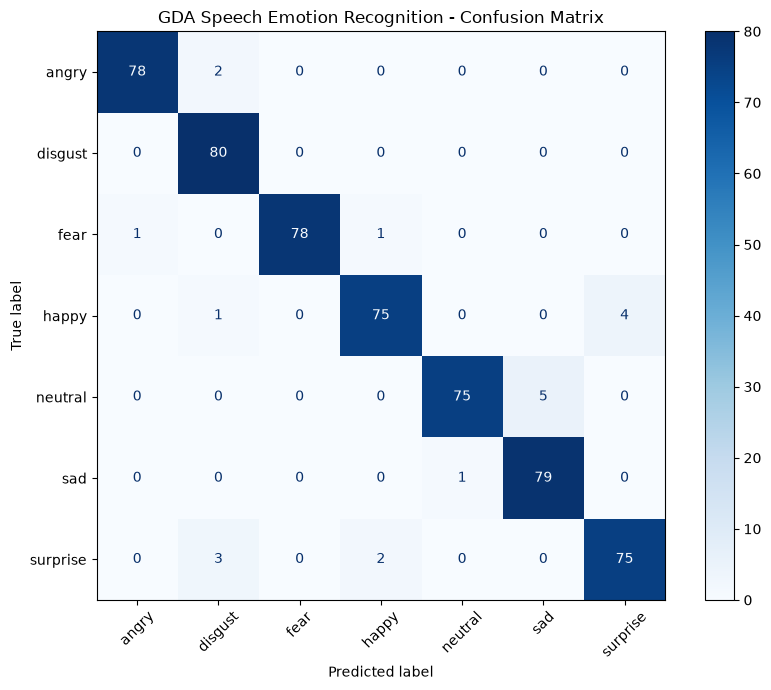

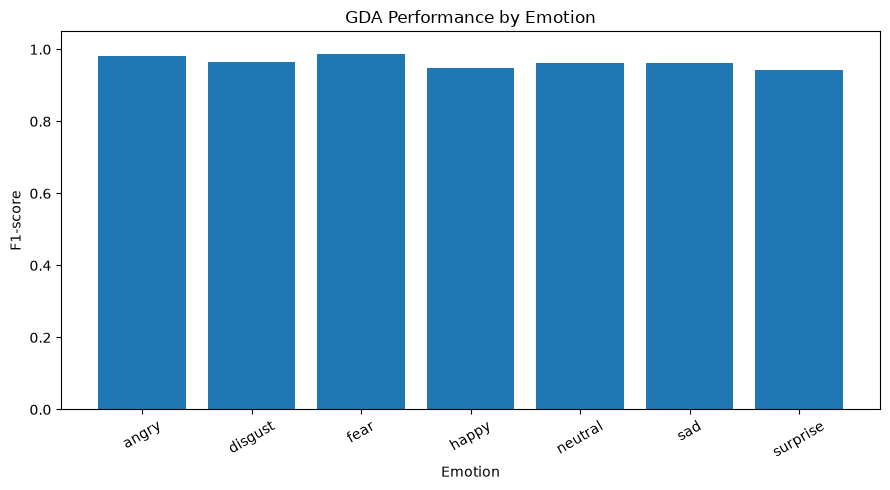

In [10]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_fscore_support

# 1. Confusion matrix
class_labels = list(classes)

cm = confusion_matrix(
    y_test_array,
    gda_predictions,
    labels=class_labels
)

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

ax.set_title("GDA Speech Emotion Recognition - Confusion Matrix")
plt.tight_layout()
plt.show()


# 2. Class-wise F1-score chart
precision, recall, f1_values, support = precision_recall_fscore_support(
    y_test_array,
    gda_predictions,
    labels=class_labels,
    zero_division=0
)

plt.figure(figsize=(9, 5))
plt.bar(class_labels, f1_values)
plt.ylim(0, 1.05)
plt.ylabel("F1-score")
plt.xlabel("Emotion")
plt.title("GDA Performance by Emotion")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


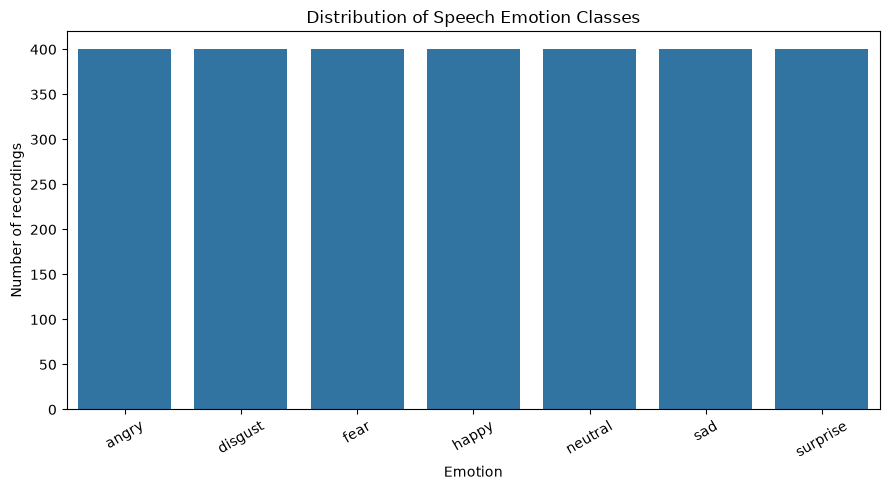

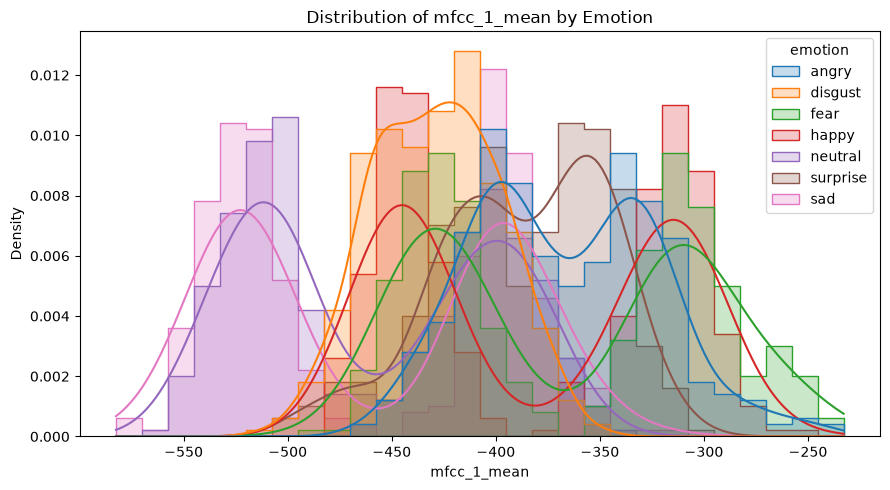

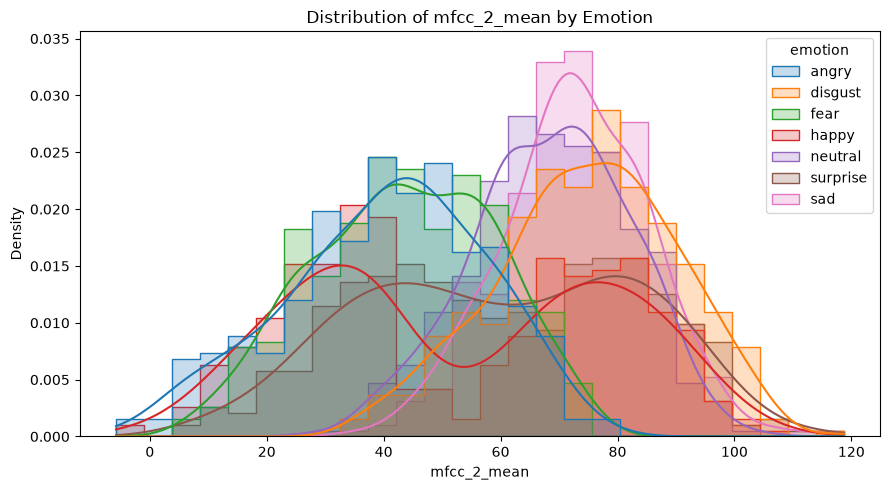

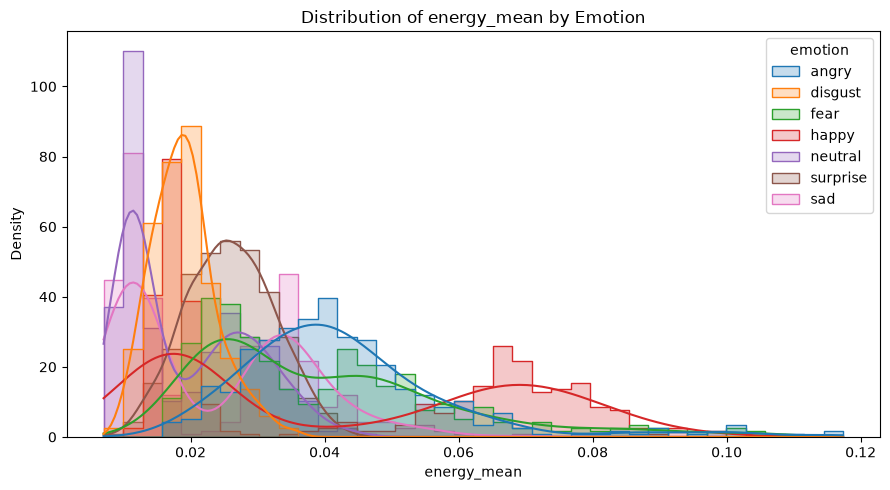

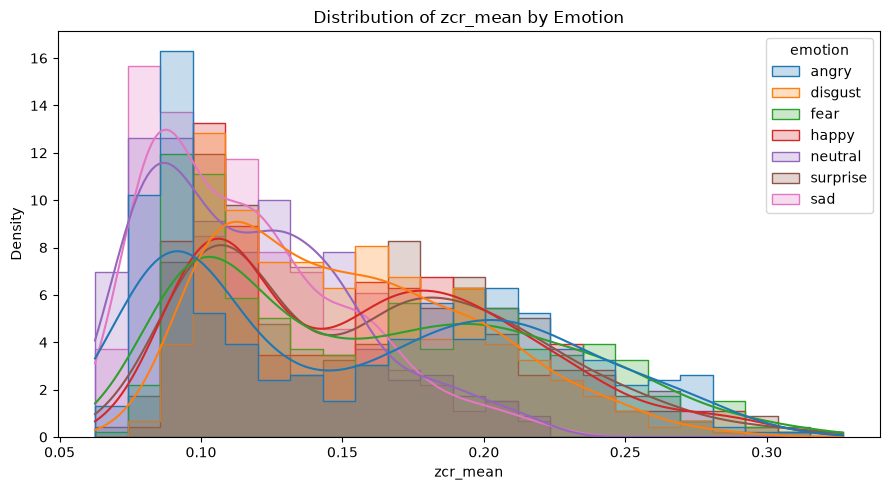

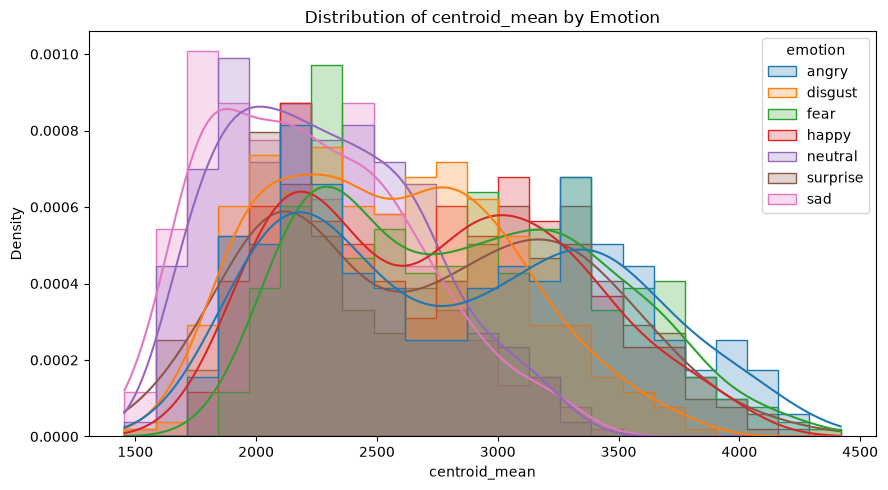

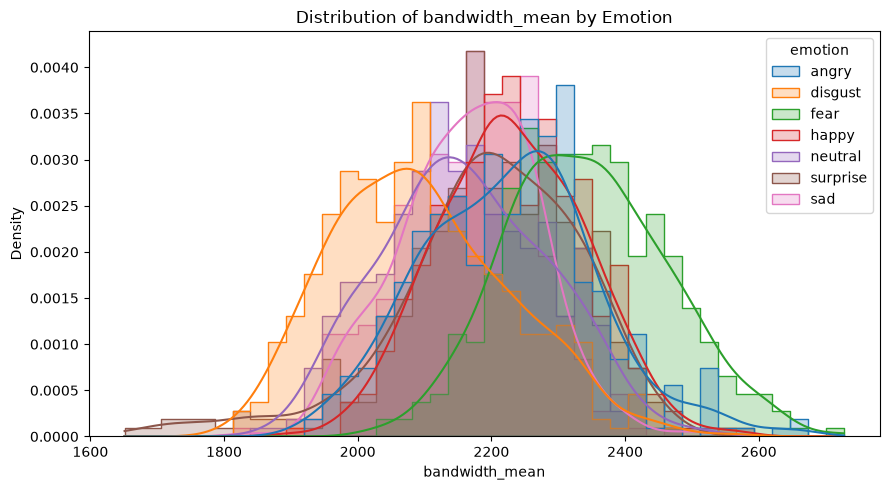

In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Emotion class distribution
plt.figure(figsize=(9, 5))
sns.countplot(data=model_df, x="emotion", order=sorted(model_df["emotion"].unique()))
plt.title("Distribution of Speech Emotion Classes")
plt.xlabel("Emotion")
plt.ylabel("Number of recordings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Select representative acoustic features for visualization
selected_features = [
    "mfcc_1_mean",
    "mfcc_2_mean",
    "energy_mean",
    "zcr_mean",
    "centroid_mean",
    "bandwidth_mean"
]

# Plot histograms by emotion
for feature in selected_features:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        data=model_df,
        x=feature,
        hue="emotion",
        element="step",
        stat="density",
        common_norm=False,
        kde=True
    )
    plt.title(f"Distribution of {feature} by Emotion")
    plt.tight_layout()
    plt.show()


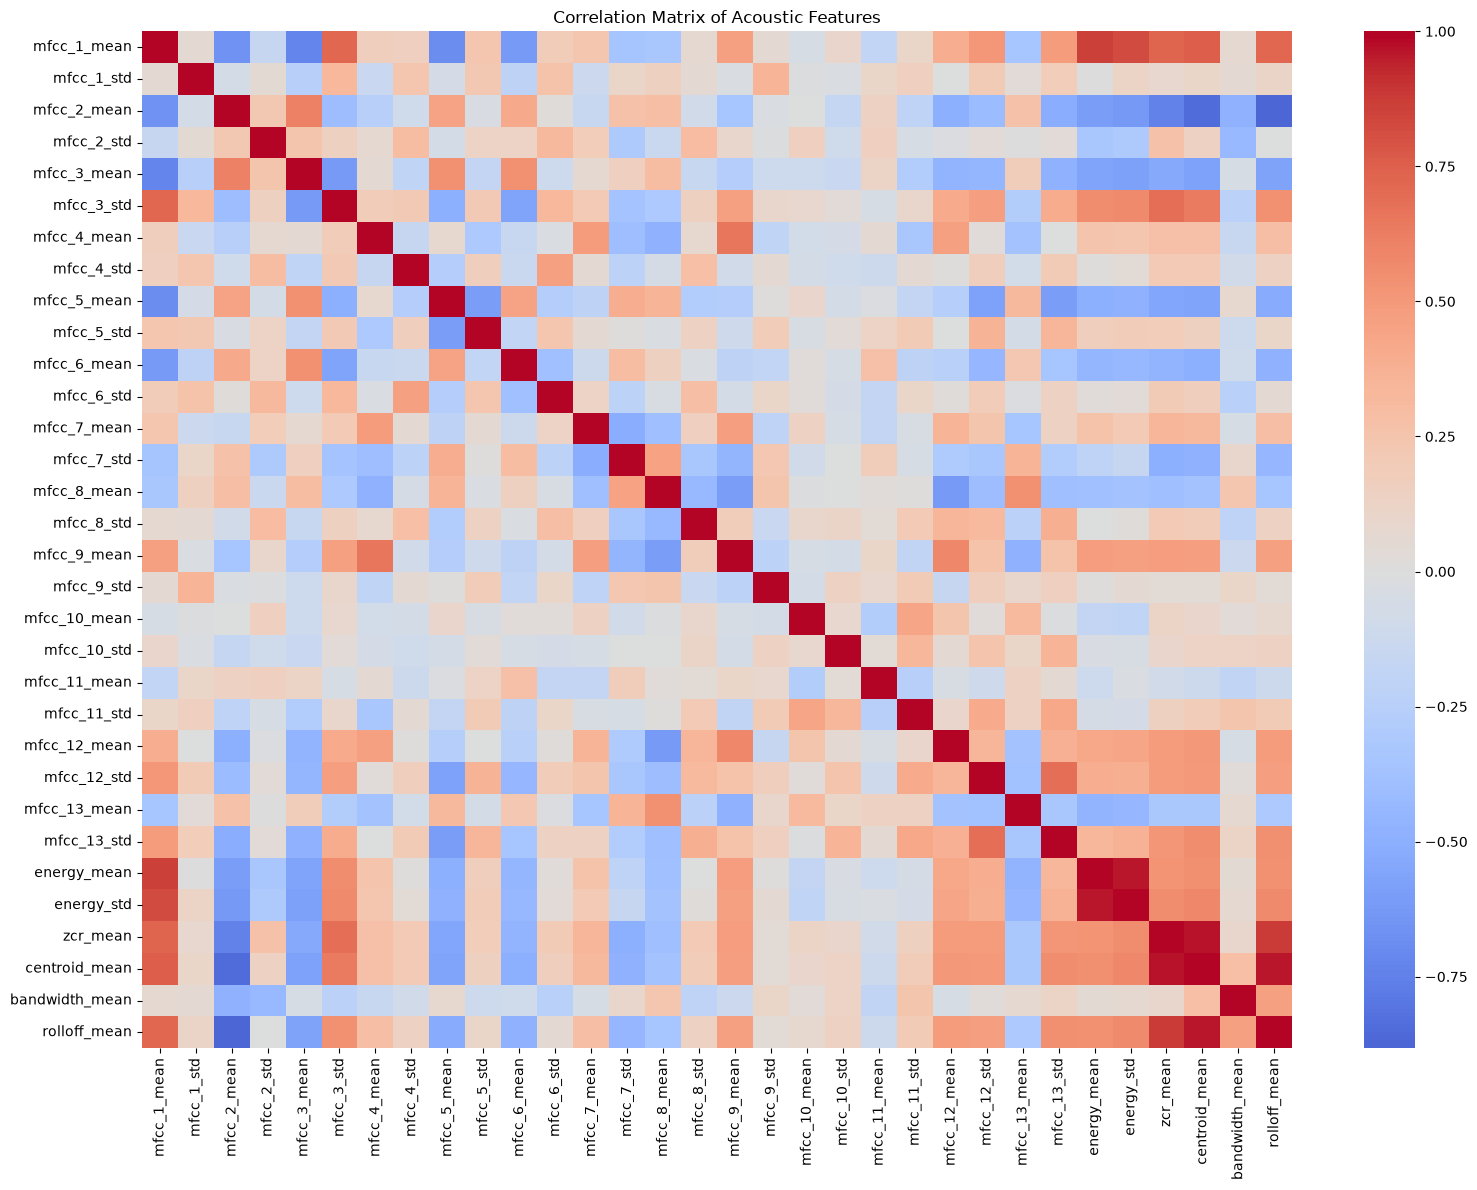

Top 10 strongest feature correlations:
zcr_mean       centroid_mean    0.965845
centroid_mean  rolloff_mean     0.962780
energy_mean    energy_std       0.962277
mfcc_2_mean    rolloff_mean    -0.882627
zcr_mean       rolloff_mean     0.876744
mfcc_1_mean    energy_mean      0.859461
mfcc_2_mean    centroid_mean   -0.850429
mfcc_1_mean    energy_std       0.816746
               centroid_mean    0.750826
mfcc_2_mean    zcr_mean        -0.746433
Name: correlation, dtype: float64


In [12]:

# Correlation matrix for all 32 numeric acoustic features
feature_cols = X_train.columns
correlation_matrix = model_df[feature_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True
)
plt.title("Correlation Matrix of Acoustic Features")
plt.tight_layout()
plt.show()

# Display the strongest feature correlations, excluding self-correlations
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strong_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .sort_values(key=abs, ascending=False)
)

print("Top 10 strongest feature correlations:")
print(strong_correlations.head(10))


In [13]:

import numpy as np

def gaussian_pdf(X, mean, covariance):
    X = np.atleast_2d(X)
    mean = np.asarray(mean)
    covariance = np.asarray(covariance)

    dimension = len(mean)
    difference = X - mean

    sign, log_det = np.linalg.slogdet(covariance)
    if sign <= 0:
        raise ValueError("Covariance matrix must be positive definite.")

    inverse_covariance = np.linalg.inv(covariance)

    mahalanobis = np.sum(
        (difference @ inverse_covariance) * difference,
        axis=1
    )

    log_density = -0.5 * (
        dimension * np.log(2 * np.pi)
        + log_det
        + mahalanobis
    )

    return np.exp(log_density)

# Example: two-dimensional Gaussian
mean = np.array([0, 0])
covariance = np.array([
    [1.0, 0.6],
    [0.6, 1.5]
])

sample_points = np.array([
    [0, 0],
    [1, 1],
    [2, 2]
])

print("Gaussian PDF values:")
print(gaussian_pdf(sample_points, mean, covariance))


Gaussian PDF values:
[0.14906226 0.08428371 0.01523602]


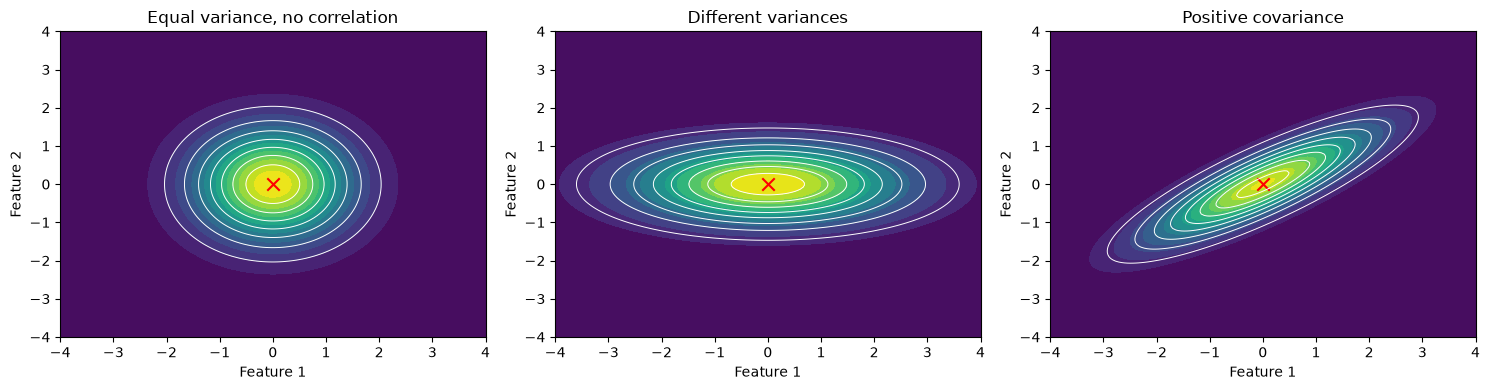

In [14]:

from matplotlib.patches import Ellipse

def plot_gaussian_contours(mean, covariance, title, ax):
    x_values = np.linspace(-4, 4, 150)
    y_values = np.linspace(-4, 4, 150)
    xx, yy = np.meshgrid(x_values, y_values)

    points = np.column_stack([xx.ravel(), yy.ravel()])
    density = gaussian_pdf(points, mean, covariance).reshape(xx.shape)

    contour = ax.contourf(xx, yy, density, levels=15, cmap="viridis")
    ax.contour(xx, yy, density, levels=8, colors="white", linewidths=0.7)
    ax.scatter(mean[0], mean[1], color="red", marker="x", s=80)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    return contour

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_gaussian_contours(
    np.array([0, 0]),
    np.array([[1, 0], [0, 1]]),
    "Equal variance, no correlation",
    axes[0]
)

plot_gaussian_contours(
    np.array([0, 0]),
    np.array([[3, 0], [0, 0.5]]),
    "Different variances",
    axes[1]
)

plot_gaussian_contours(
    np.array([0, 0]),
    np.array([[2, 1.2], [1.2, 1]]),
    "Positive covariance",
    axes[2]
)

plt.tight_layout()
plt.show()


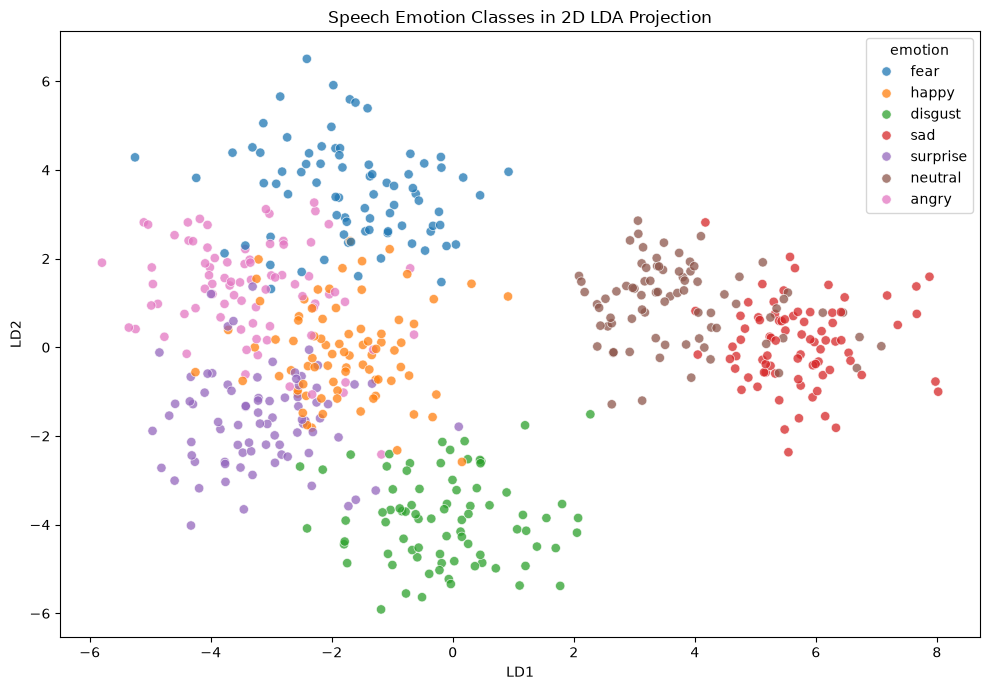

Explained discriminant variance ratios:
[0.53862052 0.22627728]


In [15]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Fit preprocessing and LDA projection on training data only
projection_scaler = StandardScaler()
X_train_scaled = projection_scaler.fit_transform(X_train)
X_test_scaled = projection_scaler.transform(X_test)

lda_projection = LinearDiscriminantAnalysis(n_components=2)
X_train_2d = lda_projection.fit_transform(X_train_scaled, y_train)
X_test_2d = lda_projection.transform(X_test_scaled)

# Visualize test data in the learned LDA space
plot_df = pd.DataFrame({
    "LD1": X_test_2d[:, 0],
    "LD2": X_test_2d[:, 1],
    "emotion": y_test.to_numpy()
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="LD1",
    y="LD2",
    hue="emotion",
    alpha=0.75,
    s=45
)
plt.title("Speech Emotion Classes in 2D LDA Projection")
plt.tight_layout()
plt.show()

print("Explained discriminant variance ratios:")
print(lda_projection.explained_variance_ratio_)


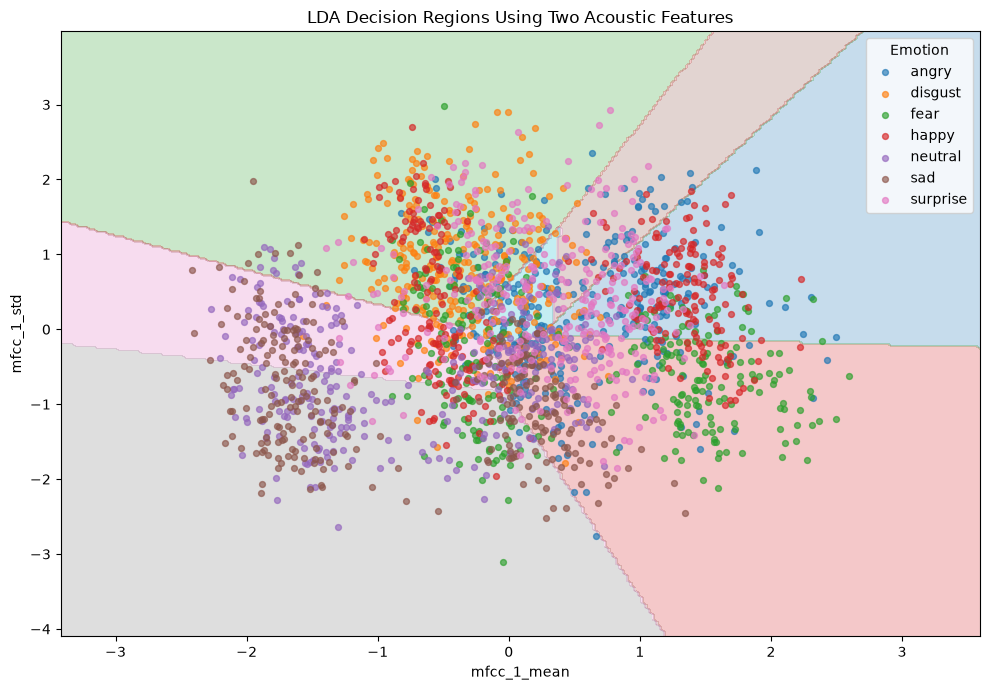

In [16]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Select two acoustic features
boundary_features = list(X_train.columns[:2])

# Standardize features
boundary_scaler = StandardScaler()
X_train_2features = boundary_scaler.fit_transform(
    X_train[boundary_features]
)

# Train LDA
boundary_model = LinearDiscriminantAnalysis()
boundary_model.fit(X_train_2features, y_train)

# Create a grid for plotting
x_min, x_max = X_train_2features[:, 0].min() - 1, X_train_2features[:, 0].max() + 1
y_min, y_max = X_train_2features[:, 1].min() - 1, X_train_2features[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Predict emotion labels for each grid point
predicted_regions = boundary_model.predict(grid)

# Convert string labels into numeric class codes
class_labels = boundary_model.classes_
label_to_number = {
    label: i for i, label in enumerate(class_labels)
}

numeric_regions = np.array([
    label_to_number[label] for label in predicted_regions
]).reshape(xx.shape)

# Plot decision regions and boundaries
plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, numeric_regions,
    levels=np.arange(len(class_labels) + 1) - 0.5,
    alpha=0.25,
    cmap="tab10"
)

# Plot training samples
for i, emotion in enumerate(class_labels):
    mask = y_train.to_numpy() == emotion
    plt.scatter(
        X_train_2features[mask, 0],
        X_train_2features[mask, 1],
        label=emotion,
        s=18,
        alpha=0.65
    )

plt.xlabel(boundary_features[0])
plt.ylabel(boundary_features[1])
plt.title("LDA Decision Regions Using Two Acoustic Features")
plt.legend(title="Emotion")
plt.tight_layout()
plt.show()


                 Model  Accuracy (%)  Macro Precision  Macro Recall  \
0     GDA from scratch         96.43           0.9651        0.9643   
1   LDA (scikit-learn)         96.43           0.9651        0.9643   
2  Logistic Regression         96.25           0.9629        0.9625   

   Macro F1-score  
0          0.9643  
1          0.9643  
2          0.9626  


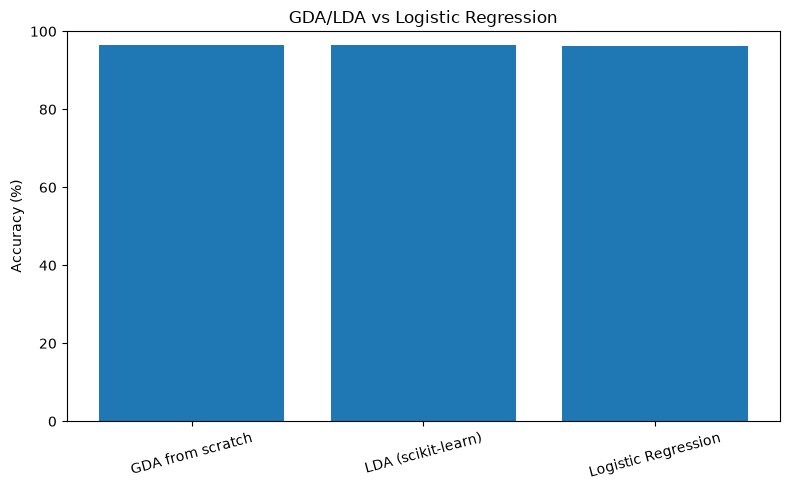

In [17]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Original LDA model
lda_comparison = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearDiscriminantAnalysis())
])

# Logistic Regression comparison
logistic_comparison = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=42))
])

models = {
    "GDA from scratch": None,
    "LDA (scikit-learn)": lda_comparison,
    "Logistic Regression": logistic_comparison
}

# Reuse predictions from the manually implemented GDA
predictions = {
    "GDA from scratch": gda_predictions
}

for name, model in models.items():
    if model is None:
        continue

    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

comparison_rows = []

for name, pred in predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
        "Macro Precision": round(
            precision_score(y_test, pred, average="macro", zero_division=0), 4
        ),
        "Macro Recall": round(
            recall_score(y_test, pred, average="macro", zero_division=0), 4
        ),
        "Macro F1-score": round(
            f1_score(y_test, pred, average="macro", zero_division=0), 4
        )
    })

comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df)

# Visual comparison of accuracy
plt.figure(figsize=(8, 5))
plt.bar(comparison_df["Model"], comparison_df["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("GDA/LDA vs Logistic Regression")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
